In [2]:
# Titanic Survival Prediction
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# load the dataset "titanic"
df = sns.load_dataset("titanic")

In [5]:
# Rows of datafrane
df.head(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


In [6]:
# Show Rows and Col of Dataset (Size of Dataset)
df.shape

(891, 15)

In [7]:
df.dtypes

,0
survived,int64
pclass,int64
sex,object
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,object
class,category
who,object


In [8]:
# Display the information of dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [9]:
#Check the missing values in every Col
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [10]:
# Describes the sastical informantion for the numerical values
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [11]:
# Identify numercial Coloums
numerical_columns = df.select_dtypes(include=np.number).columns

print("Numerical columns:")
print(numerical_columns)

Numerical columns:
Index(['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare'], dtype='object')


In [12]:
# Identify the catagorical coloums
categorical_columns = df.select_dtypes(include="object").columns

print("Categorical columns:")
print(categorical_columns)

Categorical columns:
Index(['sex', 'embarked', 'who', 'embark_town', 'alive'], dtype='object')


In [13]:
# Identify the target variable
target = "survived"

In [14]:
# Target distribution
print(df["survived"].value_counts())
print(df["survived"].value_counts(normalize=True) * 100)

survived
0    549
1    342
Name: count, dtype: int64
survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


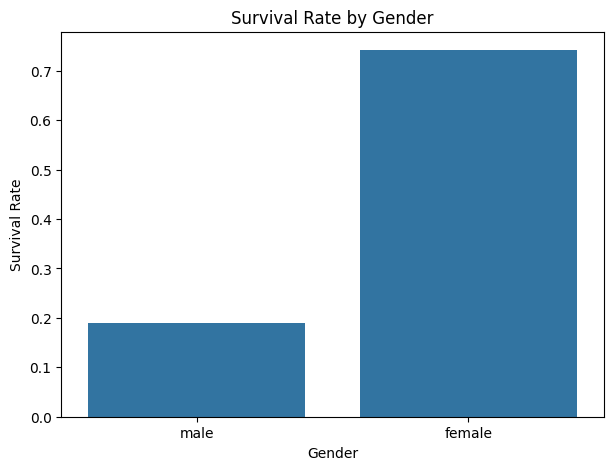

In [15]:
#visualization 1: Survival Rate by Gender
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="sex",
    y="survived",
    errorbar=None
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.show()

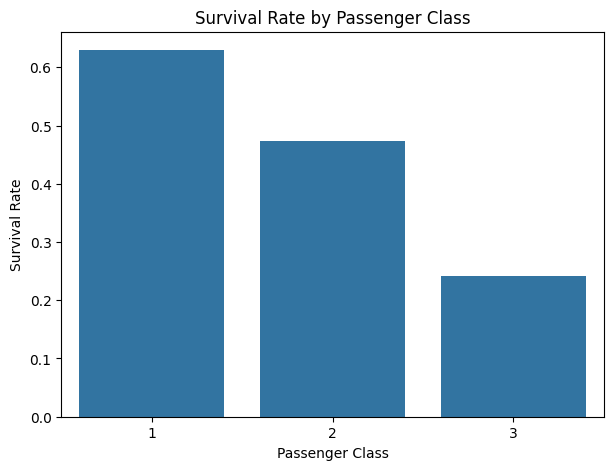

In [16]:
#visualization 2 Survival Rate by Passenger Class
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="pclass",
    y="survived",
    errorbar=None
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

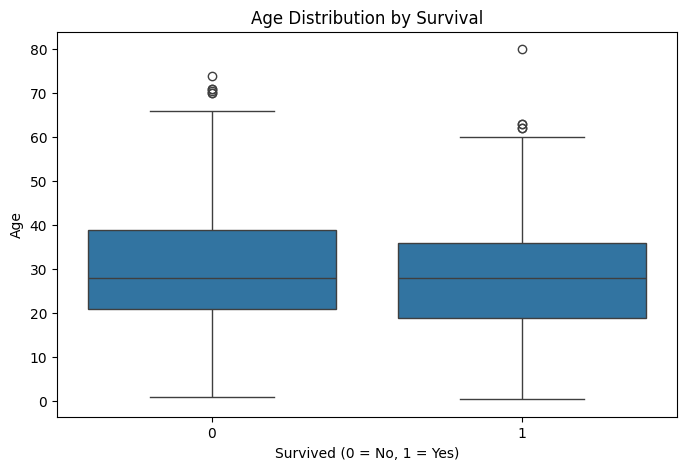

In [17]:
# Visualization 3 Age Distribution by Survival

plt.figure(figsize=(8,5))
sns.boxplot(
    data=df,
    x="survived",
    y="age"
)
plt.title("Age Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")
plt.show()




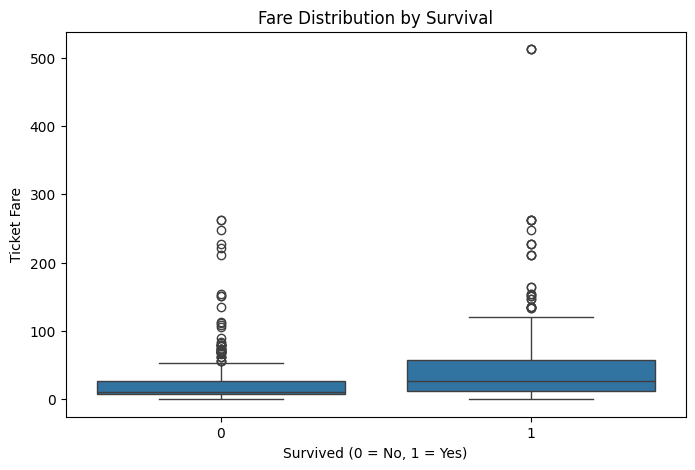

In [18]:
# Visualization 4 Fare Distribution by Survival
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="survived",
    y="fare"
)

plt.title("Fare Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Ticket Fare")
plt.show()

In [19]:

# 3. DATA PREPROCESSING

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Create a copy of the original dataset
data = df.copy()

# Remove unnecessary columns
data = data.drop(
    columns=[
        "alive",
        "class",
        "who",
        "adult_male",
        "deck",
        "embark_town",
        "alone"
    ]
)

# Check columns
print("Remaining columns:")
print(data.columns.tolist())

# Check missing values
print("\nMissing values:")
print(data.isnull().sum())

# Separate features and target
X = data.drop(columns="survived")
y = data["survived"]

print("\nX shape:", X.shape)
print("y shape:", y.shape)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

# Define numerical and categorical features
numerical_features = [
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare"
]

categorical_features = [
    "sex",
    "embarked"
]

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

Remaining columns:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']

Missing values:
survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64

X shape: (891, 7)
y shape: (891,)

Training features: (712, 7)
Testing features: (179, 7)
Training target: (712,)
Testing target: (179,)


In [20]:

# 4. FEATURE ENGINEERING

# 1. Family Size
data["FamilySize"] = data["sibsp"] + data["parch"] + 1

# 2. Is Alone
data["IsAlone"] = np.where(
    data["FamilySize"] == 1,
    1,
    0
)

# 3. Fare Per Person
data["FarePerPerson"] = data["fare"] / data["FamilySize"]

# Display engineered features
print("Engineered Features:")
display(
    data[
        [
            "sibsp",
            "parch",
            "fare",
            "FamilySize",
            "IsAlone",
            "FarePerPerson"
        ]
    ].head(10)
)

# Separate features and target again
X = data.drop(columns="survived")
y = data["survived"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Numerical features
numerical_features = [
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare",
    "FamilySize",
    "IsAlone",
    "FarePerPerson"
]

# Categorical features
categorical_features = [
    "sex",
    "embarked"
]

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combined preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Engineered Features:


,sibsp,parch,fare,FamilySize,IsAlone,FarePerPerson
0,1,0,7.2500,2,0,3.62500
1,1,0,71.2833,2,0,35.64165
2,0,0,7.9250,1,1,7.92500
3,1,0,53.1000,2,0,26.55000
4,0,0,8.0500,1,1,8.05000
5,0,0,8.4583,1,1,8.45830
6,0,0,51.8625,1,1,51.86250
7,3,1,21.0750,5,0,4.21500
8,0,2,11.1333,3,0,3.71110
9,1,0,30.0708,2,0,15.03540



Training shape: (712, 10)
Testing shape: (179, 10)


In [21]:

# 5. MODEL TRAINING

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Numerical preprocessing

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combined preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Define models

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

decision_tree = DecisionTreeClassifier(
    random_state=42
)

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Create pipelines

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", logistic_model)
    ]
)

tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", decision_tree)
    ]
)

forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", random_forest)
    ]
)

# Train models

logistic_pipeline.fit(X_train, y_train)

tree_pipeline.fit(X_train, y_train)

forest_pipeline.fit(X_train, y_train)

print("All three models trained successfully!")

# Predictions

y_pred_logistic = logistic_pipeline.predict(X_test)

y_pred_tree = tree_pipeline.predict(X_test)

y_pred_forest = forest_pipeline.predict(X_test)

print("Predictions generated successfully!")

All three models trained successfully!
Predictions generated successfully!


Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8045,0.7833,0.6812,0.7287
1,Decision Tree,0.7542,0.6812,0.6812,0.6812
2,Random Forest,0.8101,0.7778,0.7101,0.7424


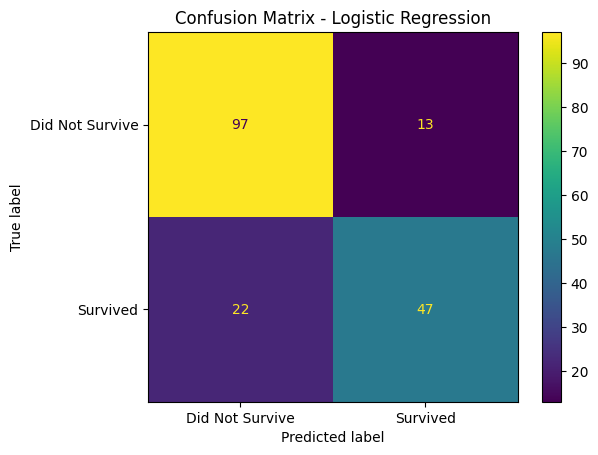

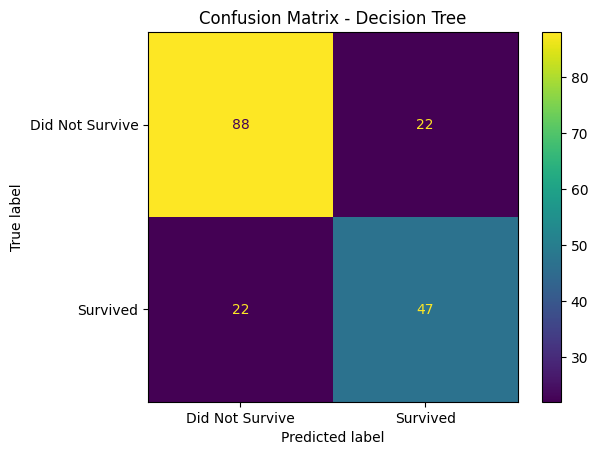

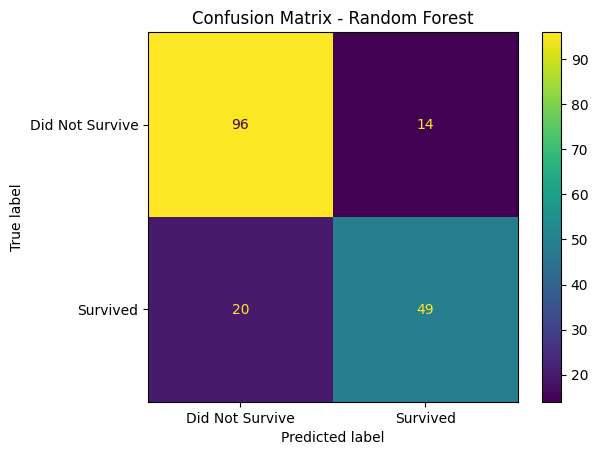

In [22]:

# 6. MODEL EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Calculate metrics

accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
precision_logistic = precision_score(y_test, y_pred_logistic)
recall_logistic = recall_score(y_test, y_pred_logistic)
f1_logistic = f1_score(y_test, y_pred_logistic)

accuracy_tree = accuracy_score(y_test, y_pred_tree)
precision_tree = precision_score(y_test, y_pred_tree)
recall_tree = recall_score(y_test, y_pred_tree)
f1_tree = f1_score(y_test, y_pred_tree)

accuracy_forest = accuracy_score(y_test, y_pred_forest)
precision_forest = precision_score(y_test, y_pred_forest)
recall_forest = recall_score(y_test, y_pred_forest)
f1_forest = f1_score(y_test, y_pred_forest)

# Comparison table

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_logistic,
        accuracy_tree,
        accuracy_forest
    ],
    "Precision": [
        precision_logistic,
        precision_tree,
        precision_forest
    ],
    "Recall": [
        recall_logistic,
        recall_tree,
        recall_forest
    ],
    "F1 Score": [
        f1_logistic,
        f1_tree,
        f1_forest
    ]
})

print("Model Comparison:")
display(results.round(4))

# Confusion Matrix - Logistic Regression

cm_logistic = confusion_matrix(y_test, y_pred_logistic)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["Did Not Survive", "Survived"]
)

disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

# Confusion Matrix - Decision Tree

cm_tree = confusion_matrix(y_test, y_pred_tree)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tree,
    display_labels=["Did Not Survive", "Survived"]
)

disp.plot()
plt.title("Confusion Matrix - Decision Tree")
plt.show()

# Confusion Matrix - Random Forest

cm_forest = confusion_matrix(y_test, y_pred_forest)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_forest,
    display_labels=["Did Not Survive", "Survived"]
)

disp.plot()
plt.title("Confusion Matrix - Random Forest")
plt.show()

Best Parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 100}

Best Cross-Validation F1 Score:
0.7550569120109742

Tuned Random Forest Performance:
Accuracy : 0.8101
Precision: 0.807
Recall   : 0.6667
F1 Score : 0.7302

Before vs After Tuning:


,Metric,Before Tuning,After Tuning
0,Accuracy,0.8101,0.8101
1,Precision,0.7778,0.8070
2,Recall,0.7101,0.6667
3,F1 Score,0.7424,0.7302


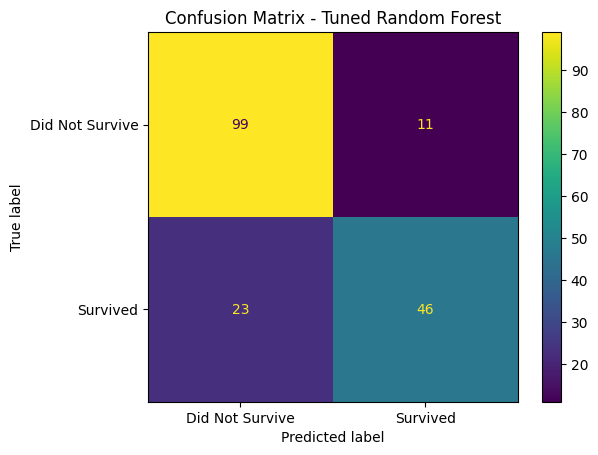

In [23]:

# 7. MODEL IMPROVEMENT - RANDOM FOREST

from sklearn.model_selection import GridSearchCV

# Define hyperparameter grid

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

# Grid Search with 5-Fold Cross Validation

grid_search = GridSearchCV(
    estimator=forest_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# Train and search for best parameters
grid_search.fit(X_train, y_train)

# Best parameters and CV score

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)

# Best tuned model

best_rf_model = grid_search.best_estimator_

# Predictions
y_pred_tuned_rf = best_rf_model.predict(X_test)

# Evaluation after tuning

tuned_accuracy = accuracy_score(y_test, y_pred_tuned_rf)
tuned_precision = precision_score(y_test, y_pred_tuned_rf)
tuned_recall = recall_score(y_test, y_pred_tuned_rf)
tuned_f1 = f1_score(y_test, y_pred_tuned_rf)

print("\nTuned Random Forest Performance:")
print("Accuracy :", round(tuned_accuracy, 4))
print("Precision:", round(tuned_precision, 4))
print("Recall   :", round(tuned_recall, 4))
print("F1 Score :", round(tuned_f1, 4))

# Before vs After

before_after = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Before Tuning": [
        accuracy_forest,
        precision_forest,
        recall_forest,
        f1_forest
    ],
    "After Tuning": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1
    ]
})

print("\nBefore vs After Tuning:")
display(before_after.round(4))

# Confusion Matrix

cm_tuned_rf = confusion_matrix(
    y_test,
    y_pred_tuned_rf
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned_rf,
    display_labels=["Did Not Survive", "Survived"]
)

disp.plot()

plt.title("Confusion Matrix - Tuned Random Forest")
plt.show()

Feature Importances:


,Feature,Importance
1,num__age,0.206426
7,num__FarePerPerson,0.169713
4,num__fare,0.163926
9,cat__sex_male,0.142692
8,cat__sex_female,0.127166
0,num__pclass,0.064333
5,num__FamilySize,0.036543
2,num__sibsp,0.022310
3,num__parch,0.021056
12,cat__embarked_S,0.014581


Top 10 Transformed Features:


,Feature,Importance
1,num__age,0.206426
7,num__FarePerPerson,0.169713
4,num__fare,0.163926
9,cat__sex_male,0.142692
8,cat__sex_female,0.127166
0,num__pclass,0.064333
5,num__FamilySize,0.036543
2,num__sibsp,0.022310
3,num__parch,0.021056
12,cat__embarked_S,0.014581


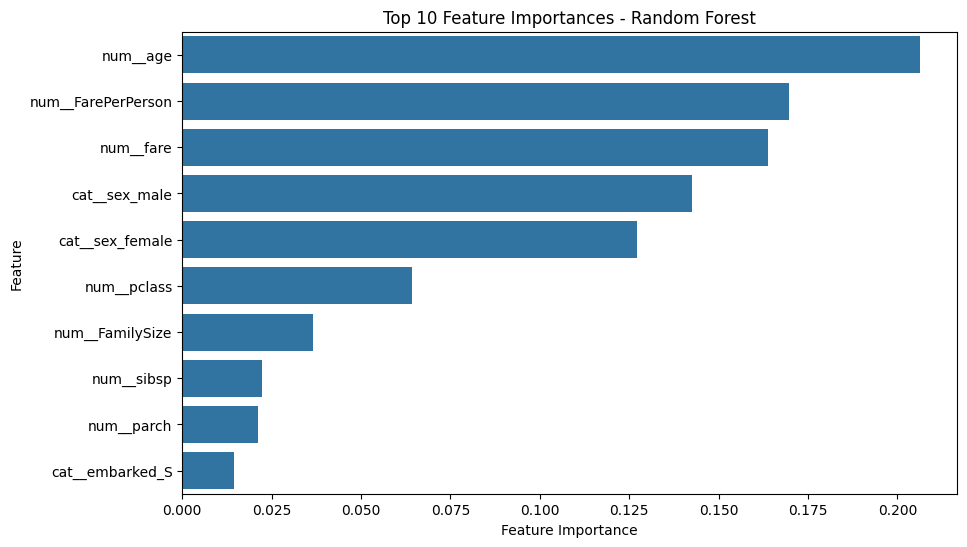

Original Feature-Level Importance:


,Original_Feature,Importance
0,sex,0.269857
1,age,0.206426
2,FarePerPerson,0.169713
3,fare,0.163926
4,pclass,0.064333
5,FamilySize,0.036543
6,embarked,0.032735
7,sibsp,0.022310
8,parch,0.021056
9,IsAlone,0.013101


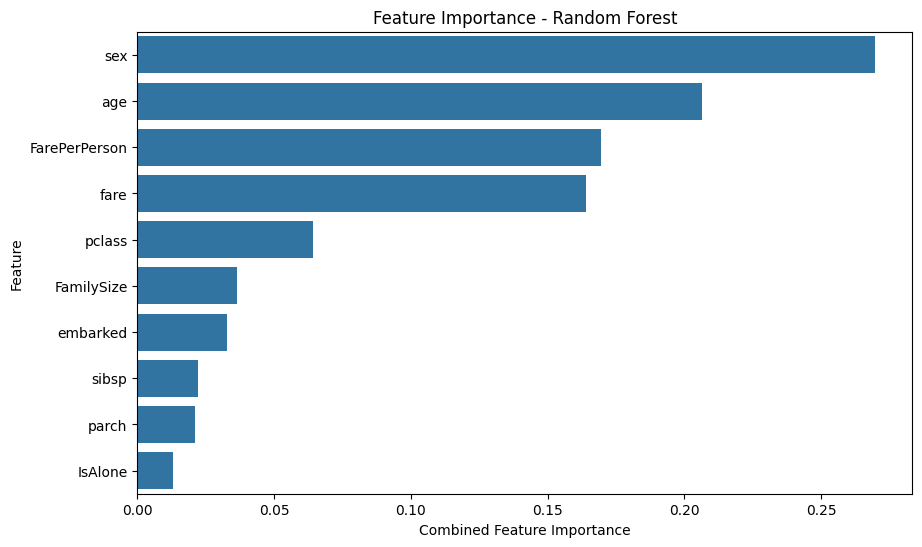

In [24]:

# 8. FEATURE IMPORTANCE

# Get feature names after preprocessing
feature_names = forest_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance from Random Forest
feature_importances = forest_pipeline.named_steps[
    "model"
].feature_importances_

# Create DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display all feature importances
print("Feature Importances:")
display(importance_df)

# Top 10 transformed features

top_features = importance_df.head(10)

print("Top 10 Transformed Features:")
display(top_features)

# Visualization

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

# Aggregate one-hot encoded features

importance_df["Original_Feature"] = (
    importance_df["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

def get_original_feature(feature_name):
    if feature_name.startswith("sex_"):
        return "sex"
    elif feature_name.startswith("embarked_"):
        return "embarked"
    else:
        return feature_name

importance_df["Original_Feature"] = (
    importance_df["Original_Feature"]
    .apply(get_original_feature)
)

aggregated_importance = (
    importance_df
    .groupby("Original_Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("Original Feature-Level Importance:")
display(aggregated_importance)

# Original feature visualization

top_original_features = aggregated_importance.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_original_features,
    x="Importance",
    y="Original_Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Combined Feature Importance")
plt.ylabel("Feature")

plt.show()

In [25]:

# FINAL MODEL COMPARISON

final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        accuracy_logistic,
        accuracy_tree,
        accuracy_forest,
        tuned_accuracy
    ],
    "Precision": [
        precision_logistic,
        precision_tree,
        precision_forest,
        tuned_precision
    ],
    "Recall": [
        recall_logistic,
        recall_tree,
        recall_forest,
        tuned_recall
    ],
    "F1 Score": [
        f1_logistic,
        f1_tree,
        f1_forest,
        tuned_f1
    ]
})

display(final_results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8045,0.7833,0.6812,0.7287
1,Decision Tree,0.7542,0.6812,0.6812,0.6812
2,Random Forest,0.8101,0.7778,0.7101,0.7424
3,Tuned Random Forest,0.8101,0.8070,0.6667,0.7302
